# CART Implementation Using a Synthetic Loan Approval Dataset

**Objective:** Implement a Classification and Regression Tree (CART) for a binary classification problem using a synthetically generated Loan Approval dataset.

The target variable is **Loan_Status** (`Approved` / `Rejected`). The notebook first computes Gini impurity and evaluates candidate binary splits by hand, then trains a CART decision tree with Scikit-learn and evaluates it.

## 1. Import required libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

pd.set_option("display.max_columns", None)

## 2. Generate the synthetic Loan Approval dataset

Each of the 40 applicants is described by four features:

| Feature | Type | Description |
|---|---|---|
| `Monthly_Income` | Numeric | Monthly income in thousand ₹ (15–120) |
| `Credit_Score` | Numeric | Credit score (550–850) |
| `Employment_Type` | Categorical | Salaried / Self-Employed / Unemployed |
| `Owns_House` | Categorical | Yes / No |

The label is produced from a hidden risk score (higher income, higher credit score, salaried employment and house ownership all raise the chance of approval) plus a little random noise, so the classes are **not perfectly separable**, as in real lending data. A fixed seed makes the dataset reproducible.

In [2]:
rng = np.random.default_rng(10)
n_applicants = 40

monthly_income = rng.integers(15, 121, n_applicants)
credit_score = rng.integers(550, 851, n_applicants)
employment_type = rng.choice(
    ["Salaried", "Self-Employed", "Unemployed"], n_applicants, p=[0.50, 0.32, 0.18]
)
owns_house = rng.choice(["Yes", "No"], n_applicants, p=[0.45, 0.55])

# Hidden approval score used only to create the labels
employment_effect = np.select(
    [employment_type == "Salaried", employment_type == "Unemployed"], [0.6, -1.5], default=0.0
)
house_effect = np.where(owns_house == "Yes", 0.4, 0.0)
risk_score = (
    (credit_score - 700) / 50
    + (monthly_income - 60) / 25
    + employment_effect
    + house_effect
    + rng.normal(0, 0.5, n_applicants)
)

loan_df = pd.DataFrame({
    "Monthly_Income": monthly_income,
    "Credit_Score": credit_score,
    "Employment_Type": employment_type,
    "Owns_House": owns_house,
    "Loan_Status": np.where(risk_score > 0, "Approved", "Rejected")
})

loan_df.to_csv("loan_approval_synthetic.csv", index=False)
loan_df.head()

,Monthly_Income,Credit_Score,Employment_Type,Owns_House,Loan_Status
0,97,786,Unemployed,Yes,Approved
1,116,618,Self-Employed,Yes,Approved
2,42,698,Salaried,No,Approved
3,37,806,Salaried,Yes,Approved
4,99,742,Salaried,No,Approved


## 3. Explore the dataset

In [3]:
print("Dataset shape:", loan_df.shape)
print("\nDataset information:")
loan_df.info()
print("\nMissing values:")
print(loan_df.isnull().sum())
print("\nTarget distribution:")
print(loan_df["Loan_Status"].value_counts())

Dataset shape: (40, 5)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 40 entries, 0 to 39
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Monthly_Income   40 non-null     int64
 1   Credit_Score     40 non-null     int64
 2   Employment_Type  40 non-null     str  
 3   Owns_House       40 non-null     str  
 4   Loan_Status      40 non-null     str  
dtypes: int64(2), str(3)
memory usage: 1.7 KB

Missing values:
Monthly_Income     0
Credit_Score       0
Employment_Type    0
Owns_House         0
Loan_Status        0
dtype: int64

Target distribution:
Loan_Status
Approved    24
Rejected    16
Name: count, dtype: int64


In [4]:
loan_df.describe(include="all")

,Monthly_Income,Credit_Score,Employment_Type,Owns_House,Loan_Status
count,40.000000,40.00000,40,40,40
unique,NaN,NaN,3,2,2
top,NaN,NaN,Salaried,Yes,Approved
freq,NaN,NaN,19,25,24
mean,73.200000,685.50000,NaN,NaN,NaN
std,33.137785,75.77497,NaN,NaN,NaN
min,15.000000,556.00000,NaN,NaN,NaN
25%,41.250000,623.75000,NaN,NaN,NaN
50%,73.000000,680.50000,NaN,NaN,NaN
75%,102.250000,747.25000,NaN,NaN,NaN


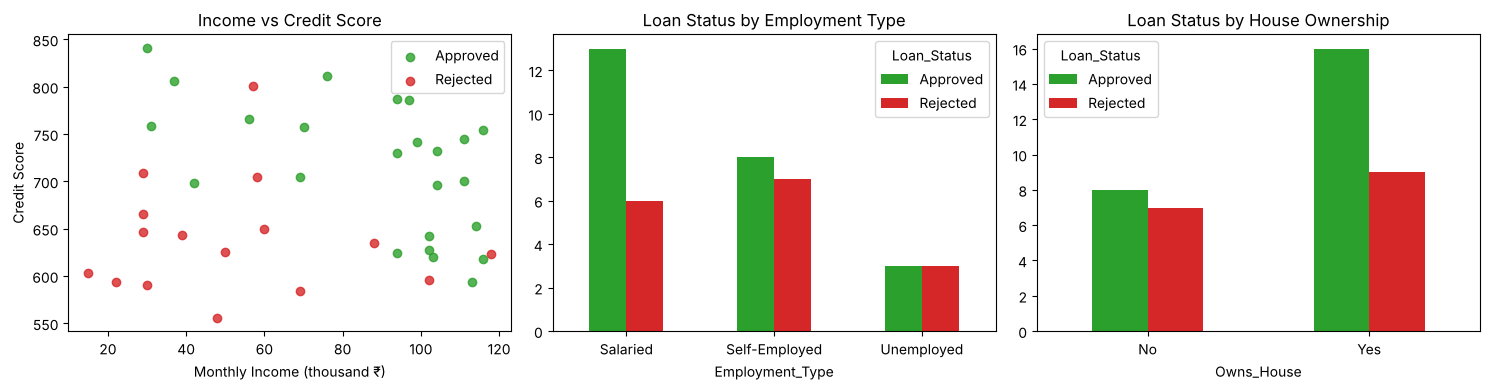

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for status, colour in [("Approved", "tab:green"), ("Rejected", "tab:red")]:
    subset = loan_df[loan_df["Loan_Status"] == status]
    axes[0].scatter(subset["Monthly_Income"], subset["Credit_Score"], label=status, c=colour, alpha=0.8)
axes[0].set_xlabel("Monthly Income (thousand ₹)")
axes[0].set_ylabel("Credit Score")
axes[0].set_title("Income vs Credit Score")
axes[0].legend()

pd.crosstab(loan_df["Employment_Type"], loan_df["Loan_Status"]).plot(
    kind="bar", ax=axes[1], color=["tab:green", "tab:red"], rot=0)
axes[1].set_title("Loan Status by Employment Type")

pd.crosstab(loan_df["Owns_House"], loan_df["Loan_Status"]).plot(
    kind="bar", ax=axes[2], color=["tab:green", "tab:red"], rot=0)
axes[2].set_title("Loan Status by House Ownership")

plt.tight_layout()
plt.show()

## 4. Separate features and target

In [6]:
X = loan_df.drop(columns="Loan_Status")
y = loan_df["Loan_Status"]

print("Features:")
display(X.head())
print("Target:")
display(y.head())

Features:


,Monthly_Income,Credit_Score,Employment_Type,Owns_House
0,97,786,Unemployed,Yes
1,116,618,Self-Employed,Yes
2,42,698,Salaried,No
3,37,806,Salaried,Yes
4,99,742,Salaried,No


Target:


0    Approved
1    Approved
2    Approved
3    Approved
4    Approved
Name: Loan_Status, dtype: str

## 5. Calculate Gini impurity

For a node with class proportions $p_k$, Gini impurity is

$$Gini = 1 - \sum_k p_k^2$$

A pure node (one class only) has Gini 0; for two classes the maximum is 0.5 (a 50/50 mix).

In [7]:
def gini(labels):
    p = labels.value_counts(normalize=True).to_numpy()
    return 1.0 - np.sum(p ** 2)

root_gini = gini(y)
counts = y.value_counts()
print(f"Approved = {counts['Approved']}, Rejected = {counts['Rejected']}")
print(f"Root (parent) Gini impurity: {root_gini:.4f}")

Approved = 24, Rejected = 16
Root (parent) Gini impurity: 0.4800


## 6. Weighted child Gini and Gini reduction

CART always makes **binary** splits. For a split into left (L) and right (R) children:

$$Gini_{split} = \frac{n_L}{n}Gini(L) + \frac{n_R}{n}Gini(R), \qquad \Delta Gini = Gini_{parent} - Gini_{split}$$

- **Numeric features:** candidate thresholds are midpoints between consecutive sorted unique values (`feature <= t`).
- **Categorical features:** every possible two-group partition of the categories is tested (for 3 categories that is 3 partitions; for 2 categories just 1).

In [8]:
from itertools import combinations

def split_score(mask, target, description):
    mask = np.asarray(mask, dtype=bool)
    left, right = target[mask], target[~mask]
    if len(left) == 0 or len(right) == 0:
        return None
    n = len(target)
    weighted = len(left) / n * gini(left) + len(right) / n * gini(right)
    return {
        "Split": description,
        "Left n": len(left),
        "Right n": len(right),
        "Weighted Child Gini": weighted,
        "Gini Reduction": gini(target) - weighted
    }

def candidate_splits(feature, target, name):
    rows = []
    if pd.api.types.is_numeric_dtype(feature):
        values = np.sort(feature.unique())
        for t in (values[:-1] + values[1:]) / 2:
            rows.append(split_score(feature <= t, target, f"{name} <= {t:.1f}"))
    else:
        cats = sorted(feature.unique())
        seen = set()
        for r in range(1, len(cats)):
            for group in combinations(cats, r):
                rest = tuple(c for c in cats if c not in group)
                key = frozenset([group, rest])
                if key in seen:
                    continue
                seen.add(key)
                rows.append(split_score(feature.isin(group), target,
                                        f"{name} in {{{', '.join(group)}}}"))
    return [r for r in rows if r]

## 7. Find the best manual binary split

In [9]:
all_splits = []
for col in X.columns:
    all_splits.extend(candidate_splits(X[col], y, col))

split_table = (pd.DataFrame(all_splits)
               .sort_values("Gini Reduction", ascending=False)
               .reset_index(drop=True))

display(split_table.head(10))

# Best split for each feature
best_per_feature = (split_table.assign(Feature=split_table["Split"].str.split().str[0])
                    .groupby("Feature", sort=False).head(1))
print("Best split per feature:")
display(best_per_feature[["Feature", "Split", "Gini Reduction"]].reset_index(drop=True))

best = split_table.iloc[0]
print(f"Best overall split: {best['Split']}")
print(f"Gini reduction: {best['Gini Reduction']:.4f}")

,Split,Left n,Right n,Weighted Child Gini,Gini Reduction
0,Monthly_Income <= 69.5,19,21,0.333835,0.146165
1,Monthly_Income <= 64.5,17,23,0.341688,0.138312
2,Monthly_Income <= 91.0,22,18,0.343434,0.136566
3,Monthly_Income <= 73.0,20,20,0.355000,0.125000
4,Credit_Score <= 680.5,20,20,0.355000,0.125000
5,Credit_Score <= 651.5,18,22,0.363636,0.116364
6,Credit_Score <= 719.5,26,14,0.363736,0.116264
7,Monthly_Income <= 59.0,16,24,0.369792,0.110208
8,Credit_Score <= 697.0,21,19,0.373935,0.106065
9,Monthly_Income <= 82.0,21,19,0.373935,0.106065


Best split per feature:


,Feature,Split,Gini Reduction
0,Monthly_Income,Monthly_Income <= 69.5,0.146165
1,Credit_Score,Credit_Score <= 680.5,0.125000
2,Employment_Type,Employment_Type in {Salaried},0.012832
3,Owns_House,Owns_House in {No},0.005333


Best overall split: Monthly_Income <= 69.5
Gini reduction: 0.1462


## 8. Prepare training and testing data

An 80:20 split, stratified on the target so that both sets keep a similar Approved/Rejected ratio.

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)
print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(2))
print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(2))

Training set shape: (32, 4)
Testing set shape: (8, 4)

Training target distribution:
Loan_Status
Approved    0.59
Rejected    0.41
Name: proportion, dtype: float64

Testing target distribution:
Loan_Status
Approved    0.62
Rejected    0.38
Name: proportion, dtype: float64


## 9. Preprocess the features

Scikit-learn's tree needs numeric input, so the two categorical columns are one-hot encoded. Numeric columns pass through unchanged (trees do not need scaling). The encoder is fitted inside the pipeline on training data only.

In [11]:
num_cols = ["Monthly_Income", "Credit_Score"]
cat_cols = ["Employment_Type", "Owns_House"]

preprocess = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
        ("num", "passthrough", num_cols)
    ]
)

## 10. Build and train the CART model

`criterion="gini"` makes the tree choose splits by Gini reduction. `max_depth=4` limits tree growth to reduce overfitting on this small dataset.

In [12]:
cart_model = Pipeline(steps=[
    ("preprocess", preprocess),
    ("cart", DecisionTreeClassifier(
        criterion="gini",
        max_depth=4,
        random_state=42
    ))
])

cart_model.fit(X_train, y_train)
print("CART model trained.")
print("Tree depth:", cart_model.named_steps["cart"].get_depth())
print("Number of leaves:", cart_model.named_steps["cart"].get_n_leaves())

CART model trained.
Tree depth: 4
Number of leaves: 7


### Check: does the manual Gini calculation agree with Scikit-learn?

The manual search in Section 7 used all 40 rows, while the tree is trained on the 32 training rows only, so the root splits can differ. Re-running the manual search on the training data should reproduce the tree's root split exactly.

In [13]:
train_splits = []
for col in X_train.columns:
    train_splits.extend(candidate_splits(X_train[col].reset_index(drop=True),
                                         y_train.reset_index(drop=True), col))
manual_root = max(train_splits, key=lambda r: r["Gini Reduction"])

root = cart_model.named_steps["cart"].tree_
root_feature = cart_model.named_steps["preprocess"].get_feature_names_out()[root.feature[0]]
print(f"Manual best split on training data : {manual_root['Split']}  (Gini reduction {manual_root['Gini Reduction']:.4f})")
print(f"Scikit-learn root split            : {root_feature} <= {root.threshold[0]:.1f}")

Manual best split on training data : Credit_Score <= 680.5  (Gini reduction 0.1582)
Scikit-learn root split            : num__Credit_Score <= 680.5


## 11. Make predictions

In [14]:
y_pred = cart_model.predict(X_test)

comparison = X_test.copy()
comparison["Actual"] = y_test.values
comparison["Predicted"] = y_pred
comparison["Correct"] = comparison["Actual"] == comparison["Predicted"]
display(comparison)

,Monthly_Income,Credit_Score,Employment_Type,Owns_House,Actual,Predicted,Correct
8,103,620,Self-Employed,Yes,Approved,Approved,True
25,76,811,Salaried,No,Approved,Approved,True
7,30,841,Salaried,No,Approved,Approved,True
16,15,603,Salaried,No,Rejected,Rejected,True
31,113,594,Salaried,Yes,Approved,Approved,True
30,29,709,Salaried,Yes,Rejected,Approved,False
15,104,732,Self-Employed,Yes,Approved,Approved,True
22,22,594,Salaried,Yes,Rejected,Rejected,True


## 12. Evaluate the model

In [15]:
train_acc = accuracy_score(y_train, cart_model.predict(X_train))
test_acc = accuracy_score(y_test, y_pred)
print(f"Training accuracy: {train_acc * 100:.2f} %")
print(f"Testing accuracy:  {test_acc * 100:.2f} %")

print("\nClassification Report (test set):")
print(classification_report(y_test, y_pred, zero_division=0))

Training accuracy: 96.88 %
Testing accuracy:  87.50 %

Classification Report (test set):
              precision    recall  f1-score   support

    Approved       0.83      1.00      0.91         5
    Rejected       1.00      0.67      0.80         3

    accuracy                           0.88         8
   macro avg       0.92      0.83      0.85         8
weighted avg       0.90      0.88      0.87         8



## 13. Confusion matrix

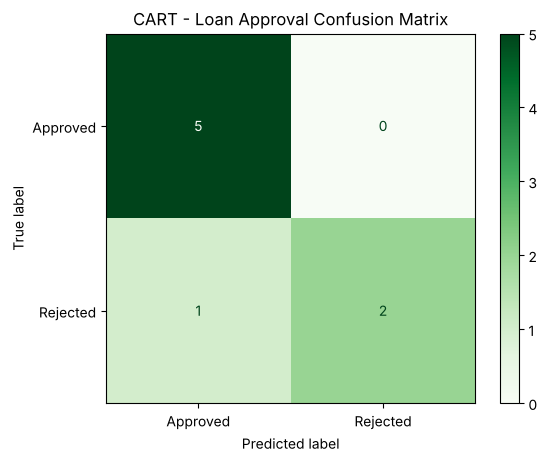

In [16]:
labels = ["Approved", "Rejected"]
cm = confusion_matrix(y_test, y_pred, labels=labels)
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels).plot(cmap="Greens")
plt.title("CART - Loan Approval Confusion Matrix")
plt.show()

## 14. Visualize the decision tree

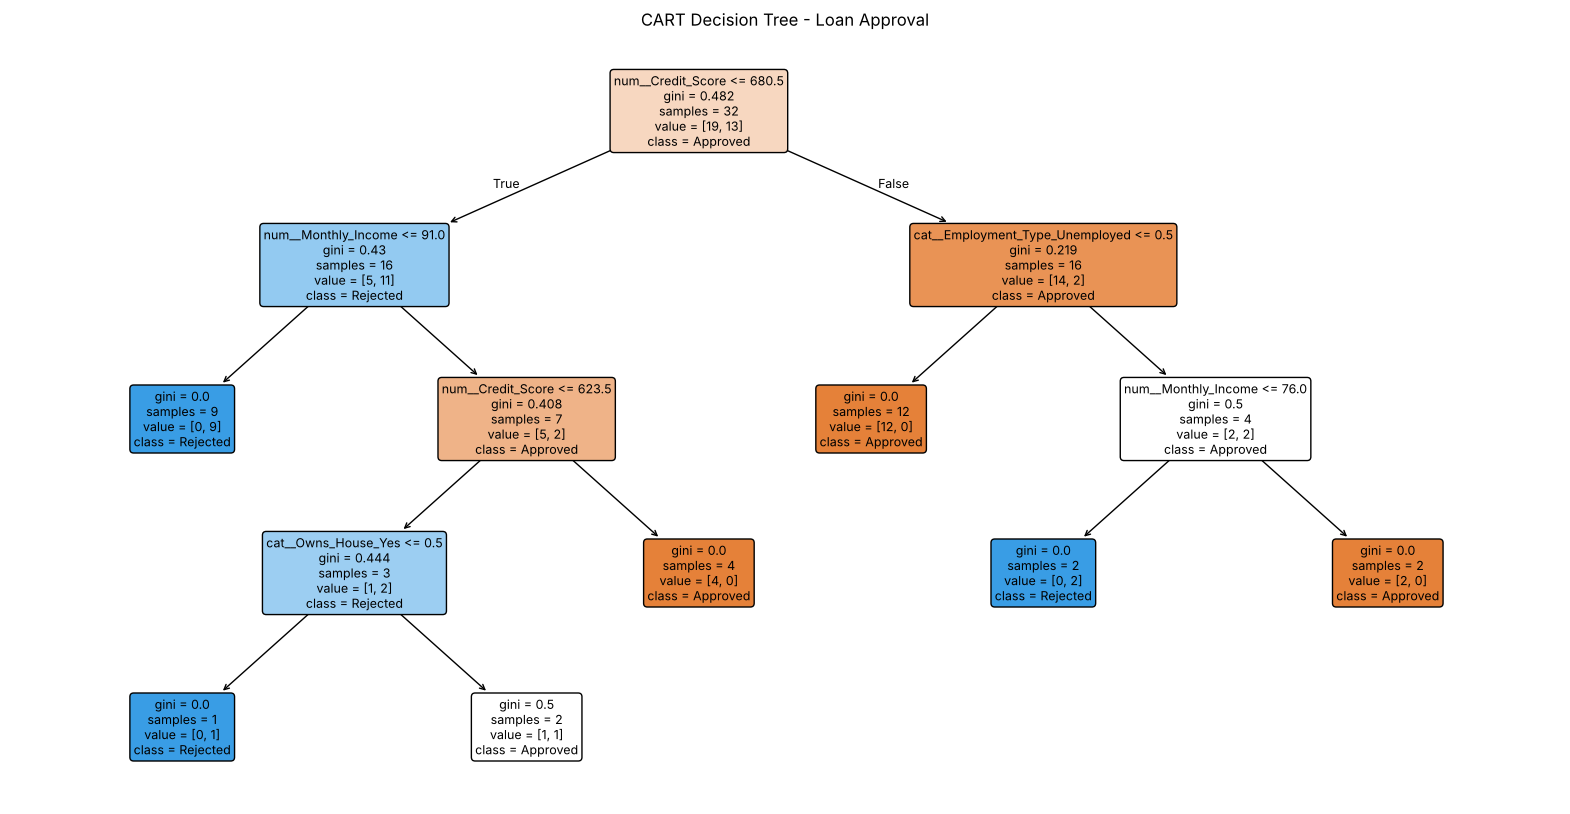

|--- num__Credit_Score <= 680.50
|   |--- num__Monthly_Income <= 91.00
|   |   |--- class: Rejected
|   |--- num__Monthly_Income >  91.00
|   |   |--- num__Credit_Score <= 623.50
|   |   |   |--- cat__Owns_House_Yes <= 0.50
|   |   |   |   |--- class: Rejected
|   |   |   |--- cat__Owns_House_Yes >  0.50
|   |   |   |   |--- class: Approved
|   |   |--- num__Credit_Score >  623.50
|   |   |   |--- class: Approved
|--- num__Credit_Score >  680.50
|   |--- cat__Employment_Type_Unemployed <= 0.50
|   |   |--- class: Approved
|   |--- cat__Employment_Type_Unemployed >  0.50
|   |   |--- num__Monthly_Income <= 76.00
|   |   |   |--- class: Rejected
|   |   |--- num__Monthly_Income >  76.00
|   |   |   |--- class: Approved



In [17]:
tree_clf = cart_model.named_steps["cart"]
feature_names = cart_model.named_steps["preprocess"].get_feature_names_out()

plt.figure(figsize=(20, 10))
plot_tree(
    tree_clf,
    feature_names=feature_names,
    class_names=tree_clf.classes_,
    filled=True,
    rounded=True,
    fontsize=9
)
plt.title("CART Decision Tree - Loan Approval")
plt.show()

print(export_text(tree_clf, feature_names=list(feature_names)))

## 15. Feature importance

Gini importance is the total Gini reduction contributed by each feature across all splits in the tree.

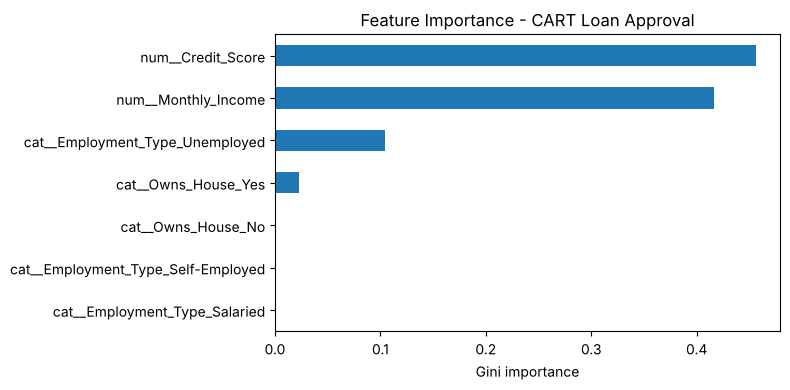

,Importance
num__Credit_Score,0.4562
num__Monthly_Income,0.4168
cat__Employment_Type_Unemployed,0.1039
cat__Owns_House_Yes,0.0231
cat__Owns_House_No,0.0000
cat__Employment_Type_Salaried,0.0000
cat__Employment_Type_Self-Employed,0.0000


In [18]:
importance = (pd.Series(tree_clf.feature_importances_, index=feature_names)
              .sort_values(ascending=True))

importance.plot(kind="barh", figsize=(8, 4), color="tab:blue")
plt.xlabel("Gini importance")
plt.title("Feature Importance - CART Loan Approval")
plt.tight_layout()
plt.show()

display(importance.sort_values(ascending=False).round(4).to_frame("Importance"))

## 16. Predict the loan status for new applicants

In [19]:
new_applicants = pd.DataFrame({
    "Monthly_Income": [75, 30],
    "Credit_Score": [780, 610],
    "Employment_Type": ["Salaried", "Unemployed"],
    "Owns_House": ["Yes", "No"]
})

new_applicants["Predicted_Loan_Status"] = cart_model.predict(new_applicants)
display(new_applicants)

,Monthly_Income,Credit_Score,Employment_Type,Owns_House,Predicted_Loan_Status
0,75,780,Salaried,Yes,Approved
1,30,610,Unemployed,No,Rejected


## 17. Conclusion

- Generated a reproducible synthetic Loan Approval dataset (40 applicants, 2 numeric and 2 categorical features, binary target with 24 Approved / 16 Rejected).
- Computed the root Gini impurity (0.48), the weighted child Gini and the Gini reduction for every candidate binary split, including all two-group partitions of the categorical features.
- On the full dataset the strongest manual split was **Monthly_Income <= 69.5** (Gini reduction ≈ 0.146), followed closely by **Credit_Score <= 680.5**. Categorical features gave much smaller reductions on their own.
- Re-running the manual search on the training rows reproduced the Scikit-learn tree's root split, confirming the manual Gini calculation matches the library.
- Trained a CART classifier with `DecisionTreeClassifier(criterion="gini", max_depth=4)`: training accuracy 96.88 %, test accuracy 87.50 % (one Rejected applicant was predicted as Approved). Because the labels include noise, the model does not reach 100 %, which is a more realistic outcome.
- Credit score and monthly income were the most important features, with being unemployed as the main categorical factor.

**Result:** CART was implemented successfully to predict whether a loan application is approved or rejected from an applicant's income, credit score, employment type and house ownership.